# Agricultural Supply Chain Analytics — Complete Solution

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
DATA=Path('../02_Data/Clean_Reference'); OUT=Path('../07_Solution_Outputs')
harvest=pd.read_csv(DATA/'fact_harvest_lots.csv',parse_dates=['harvest_date'])
inbound=pd.read_csv(DATA/'fact_inbound_shipments.csv',parse_dates=['dispatch_date'])
orders=pd.read_csv(DATA/'fact_customer_orders.csv',parse_dates=['order_date'])
print('Lots',len(harvest),'Inbound',len(inbound),'Orders',len(orders))

Lots 22000 Inbound 21254 Orders 30000


## 1. Executive KPI baseline

In [2]:
import json
base=json.loads((OUT/'executive_baseline.json').read_text())
pd.Series(base)

procurement_spend_inr        47601092811.160004
sales_inr                         7529226708.73
avg_fill_rate                          0.941459
otif                                   0.109333
quality_rejection_rate                  0.06224
transport_loss_rate                    0.058052
spoilage_value_inr                  578764139.0
temp_excursion_rate                    0.529265
forecast_wape                          0.103758
recall_lot                           LOT0005168
recall_affected_customers                    19
dtype: object

## 2. Supplier performance

In [3]:
supplier=pd.read_csv(OUT/'supplier_performance_scorecard.csv')
display(supplier.head(10)); display(supplier.groupby('risk_band',observed=False).agg(farms=('farm_id','nunique'),spend=('procurement_spend_inr','sum'),avg_score=('supplier_score','mean')))

,farm_id,lots,accepted_qty_kg,harvest_qty_kg,procurement_spend_inr,avg_ppv_pct,avg_yield_attainment,avg_rejection_rate,grade_a_share,pesticide_pass_rate,region,supplier_tier,certification,reliability_score_source,supplier_score,risk_band
0,FRM02438,1,0.0,30484.0,0.00,0.005181,0.945409,1.000000,0.000000,0.000000,Haryana,Development,Organic,0.9032,38.3,High Risk
1,FRM00695,1,0.0,3230.0,0.00,0.003438,1.012539,1.000000,0.000000,1.000000,Maharashtra,Preferred,GlobalG.A.P.,0.7520,54.8,High Risk
2,FRM01806,5,56721.0,105374.0,3430904.49,-0.027166,0.979046,0.422074,0.000000,0.600000,Uttar Pradesh,Approved,Local GAP,0.8280,62.9,Watch
3,FRM01514,5,24085.0,65231.0,929273.65,-0.012819,1.046952,0.423148,0.000000,0.600000,Tamil Nadu,Preferred,Local GAP,0.8291,63.4,Watch
4,FRM01061,3,16112.0,34741.0,579842.40,0.033278,1.011095,0.345764,0.000000,0.666667,Madhya Pradesh,Preferred,Local GAP,0.7899,64.4,Watch
5,FRM01167,3,178735.0,241821.0,4466930.90,-0.052194,0.939625,0.354733,0.000000,0.666667,Rajasthan,Approved,Organic,0.4811,64.6,Watch
6,FRM00693,9,24831.0,53269.0,1076491.22,-0.018911,0.940282,0.350676,0.000000,0.666667,Haryana,Approved,Organic,0.4602,64.7,Watch
7,FRM01911,6,35204.0,72466.0,1121560.39,-0.029858,1.003683,0.512436,0.000000,0.833333,Rajasthan,Development,Organic,0.8667,64.7,Watch
8,FRM02486,8,424230.0,756595.0,29234163.81,-0.012056,1.001129,0.501031,0.000000,0.875000,Uttar Pradesh,Approved,NaN,0.8398,65.6,Watch
9,FRM00084,9,129389.0,168293.0,8337776.74,-0.037436,1.062049,0.459084,0.111111,0.666667,Punjab,Approved,Local GAP,0.8273,65.7,Watch


,farms,spend,avg_score
risk_band,,,
Good,1137,1.819187e+10,79.874406
High Risk,2,0.000000e+00,46.550000
Strategic,1820,2.905465e+10,91.747802
Watch,37,3.545790e+08,67.429730


## 3. Cold-chain / carrier performance

In [4]:
carrier=pd.read_csv(OUT/'carrier_cold_chain_scorecard.csv'); display(carrier.sort_values('carrier_score').head(10))

,carrier_id,shipments,avg_delay_hours,temp_excursion_rate,inbound_loss_rate,freight_inr_per_kg,carrier_name,fleet_type,contract_rate_inr_per_tonne_km,base_reliability,carrier_score
0,CAR013,1073,10.810624,0.779124,0.084533,0.661532,Carrier_13,Ambient,2.85,0.5500,40.0
1,CAR002,1100,10.554818,0.785455,0.084863,0.568646,Carrier_02,Ambient,2.48,0.5576,40.3
2,CAR003,1081,10.577336,0.769658,0.083820,0.597663,Carrier_03,Ambient,2.53,0.5500,40.8
3,CAR008,1047,7.168863,0.786055,0.080813,0.953617,Carrier_08,Ambient,4.03,0.7379,48.6
4,CAR020,1071,6.646685,0.801120,0.081248,0.769663,Carrier_20,Ambient,3.37,0.7768,49.4
5,CAR015,1099,6.433030,0.794359,0.080064,0.682830,Carrier_15,Ambient,2.90,0.7960,50.4
6,CAR004,1050,4.971714,0.791429,0.078369,1.230693,Carrier_04,Ambient,5.28,0.8871,54.3
7,CAR018,1038,4.608767,0.783237,0.075797,0.865418,Carrier_18,Ambient,3.77,0.9277,56.1
8,CAR009,994,3.755835,0.787726,0.075325,0.584843,Carrier_09,Ambient,2.55,0.9714,57.9
9,CAR014,1101,10.806994,0.332425,0.032108,0.757759,Carrier_14,Reefer,3.22,0.5500,62.2


## 4. Warehouse spoilage

,warehouse_id,received_qty_kg,spoilage_qty_kg,spoilage_value_inr,closing_inventory_value_inr,critical_shelf_life_lots,expired_lots,avg_temp_excursion_hours,warehouse_name,region,warehouse_type,capacity_tonnes,cold_capacity_tonnes,target_inventory_days,spoilage_rate
0,WH015,59687300.0,828387.0,44743689.0,44366789.0,17,1108,5.843340,Distribution_Centre_15,Uttar Pradesh,Cold Chain,9270.0,1287.0,26,0.013879
1,WH005,57083348.0,777301.0,43499976.0,41869275.0,15,1078,5.707529,Distribution_Centre_05,Haryana,Cold Chain,9944.0,4212.0,15,0.013617
2,WH012,56161893.0,750116.0,42288287.0,29594079.0,14,1031,6.058389,Distribution_Centre_12,Tamil Nadu,Mixed,11162.0,4399.0,13,0.013356
3,WH001,51631035.0,737160.0,41594352.0,42380939.0,11,1025,5.645235,Distribution_Centre_01,Tamil Nadu,Mixed,5093.0,7453.0,17,0.014277
4,WH004,58230198.0,707971.0,39552322.0,38916386.0,13,1114,5.437050,Distribution_Centre_04,Maharashtra,Ambient,15215.0,0.0,17,0.012158
5,WH002,53932754.0,721551.0,38434192.0,28421290.0,14,1057,6.113610,Distribution_Centre_02,Madhya Pradesh,Cold Chain,15767.0,6124.0,25,0.013379
6,WH014,52769992.0,692517.0,38146283.0,45668288.0,17,1046,5.685025,Distribution_Centre_14,Haryana,Mixed,13057.0,5049.0,17,0.013123
7,WH009,59457788.0,688854.0,38046594.0,35708028.0,11,1132,5.837208,Distribution_Centre_09,Himachal Pradesh,Mixed,4393.0,7150.0,26,0.011586
8,WH011,57825314.0,692193.0,37607876.0,30018300.0,14,1097,5.824039,Distribution_Centre_11,Punjab,Mixed,10685.0,2926.0,23,0.011970
9,WH008,57060082.0,659892.0,37184197.0,48392961.0,14,1043,5.829986,Distribution_Centre_08,Karnataka,Cold Chain,14801.0,5998.0,13,0.011565


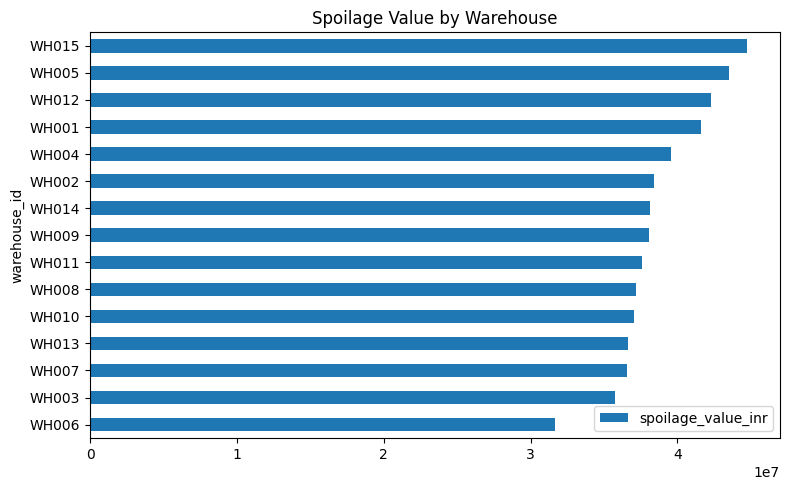

In [5]:
wh=pd.read_csv(OUT/'warehouse_spoilage_scorecard.csv'); display(wh.sort_values('spoilage_value_inr',ascending=False).head(10)); wh.sort_values('spoilage_value_inr').plot.barh(x='warehouse_id',y='spoilage_value_inr',figsize=(8,5),title='Spoilage Value by Warehouse'); plt.tight_layout(); plt.show()

## 5. Customer service

In [6]:
svc=pd.read_csv(OUT/'product_service_scorecard.csv'); display(svc[['product_name','fill_rate','otif','customer_rejection_rate','net_sales_inr']].sort_values('fill_rate'))

,product_name,fill_rate,otif,customer_rejection_rate,net_sales_inr
5,Grapes,0.937491,0.105147,0.070411,7.831313e+08
0,Apple,0.937539,0.083547,0.071664,1.230596e+09
6,Mango,0.938169,0.093023,0.072131,7.950145e+08
10,Potato,0.938525,0.094319,0.074971,3.089353e+08
12,Tomato,0.939443,0.102308,0.070405,5.169632e+08
9,Orange,0.940181,0.096890,0.069391,7.419705e+08
7,Okra,0.940364,0.103940,0.071512,4.127202e+08
4,Green Chilli,0.941023,0.084760,0.070237,4.106619e+08
1,Banana,0.941158,0.107595,0.069474,3.517008e+08
3,Cauliflower,0.941325,0.101894,0.069529,2.623662e+08


## 6. Demand forecast holdout

In [7]:
fc=pd.read_csv(OUT/'demand_forecast_holdout_results.csv',parse_dates=['month']); wape=fc.abs_error_kg.sum()/fc.ordered_qty_kg.sum(); print('WAPE',round(wape,4)); display(fc.groupby('product_id').apply(lambda g:g.abs_error_kg.sum()/g.ordered_qty_kg.sum()).sort_values().rename('WAPE'))

WAPE 0.1038


/tmp/ipykernel_1993/2262248254.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  fc=pd.read_csv(OUT/'demand_forecast_holdout_results.csv',parse_dates=['month']); wape=fc.abs_error_kg.sum()/fc.ordered_qty_kg.sum(); print('WAPE',round(wape,4)); display(fc.groupby('product_id').apply(lambda g:g.abs_error_kg.sum()/g.ordered_qty_kg.sum()).sort_values().rename('WAPE'))


product_id
PRD_BANANA    0.031432
PRD_APPLE     0.038899
PRD_GRAPE     0.051923
PRD_RICE      0.057762
PRD_POTATO    0.079782
PRD_CAULI     0.089449
PRD_WHEAT     0.096927
PRD_TOMATO    0.123261
PRD_ONION     0.123862
PRD_CAPS      0.130426
PRD_MANGO     0.136342
PRD_OKRA      0.169884
PRD_ORANGE    0.190907
PRD_CHILI     0.206497
Name: WAPE, dtype: float64

## 7. Safety stock / reorder point

In [8]:
ss=pd.read_csv(OUT/'safety_stock_reorder_point_recommendation.csv'); display(ss.sort_values('safety_stock_kg',ascending=False))

,product_id,avg_daily_demand_kg,std_daily_demand_kg,avg_lead_time_days,service_z,safety_stock_kg,reorder_point_kg,product_name,nominal_shelf_life_days,perishability_rank
0,PRD_APPLE,17502.696541,11202.985759,0.723634,1.65,15725.0,28391.0,Apple,120,3
12,PRD_TOMATO,17968.263566,10915.732998,0.727777,1.65,15365.0,28442.0,Tomato,14,3
10,PRD_POTATO,17174.862928,10514.578312,0.715189,1.65,14672.0,26955.0,Potato,75,2
8,PRD_ONION,17618.217868,10414.934109,0.717971,1.65,14561.0,27210.0,Onion,60,2
9,PRD_ORANGE,16148.301109,10265.462022,0.716336,1.65,14336.0,25904.0,Orange,55,2
11,PRD_RICE,15450.780063,9813.856352,0.707614,1.65,13621.0,24554.0,Basmati Rice,240,1
13,PRD_WHEAT,13145.630470,9116.268887,0.712749,1.65,12699.0,22069.0,Wheat,180,1
6,PRD_MANGO,13435.890145,9110.761981,0.712994,1.65,12694.0,22274.0,Mango,24,3
5,PRD_GRAPE,12274.156098,8876.533572,0.721388,1.65,12440.0,21294.0,Grapes,21,3
1,PRD_BANANA,13330.070626,8817.915881,0.714137,1.65,12295.0,21815.0,Banana,18,2


## 8. Recall traceability

In [9]:
r=pd.read_csv(OUT/'recall_traceability_summary.csv'); display(r); impacted=pd.read_csv(OUT/'recall_traceability_impacted_orders.csv'); display(impacted.head(20))

,simulated_recall_lot_id,affected_orders,affected_customers,allocated_qty_kg,sales_exposure_inr
0,LOT0005168,20,19,65071.0,2909163.12


,allocation_id,order_id,lot_id,warehouse_id,product_id_x,allocated_qty_kg,lot_expiry_date,lot_harvest_date,customer_id,order_date,delivered_qty_kg,net_sales_inr,farm_id,product_id_y,harvest_date,quality_grade,recall_case
0,ALC0000111,ORD0000111,LOT0005168,WH005,PRD_TOMATO,3833.0,2024-10-14,2024-10-01,CUS00361,2024-10-08,3833.0,181136.52,FRM01723,PRD_TOMATO,2024-10-01,A,Simulated microbial alert
1,ALC0000763,ORD0000763,LOT0005168,WH005,PRD_TOMATO,4550.0,2024-10-14,2024-10-01,CUS00361,2024-10-02,4550.0,178900.80,FRM01723,PRD_TOMATO,2024-10-01,A,Simulated microbial alert
2,ALC0001999,ORD0001999,LOT0005168,WH005,PRD_TOMATO,3298.0,2024-10-14,2024-10-01,CUS00190,2024-10-02,3298.0,145085.33,FRM01723,PRD_TOMATO,2024-10-01,A,Simulated microbial alert
3,ALC0003867,ORD0003867,LOT0005168,WH005,PRD_TOMATO,4579.0,2024-10-14,2024-10-01,CUS00139,2024-10-06,4579.0,196572.46,FRM01723,PRD_TOMATO,2024-10-01,A,Simulated microbial alert
4,ALC0005681,ORD0005681,LOT0005168,WH005,PRD_TOMATO,4429.0,2024-10-14,2024-10-01,CUS00222,2024-10-01,4429.0,217579.77,FRM01723,PRD_TOMATO,2024-10-01,A,Simulated microbial alert
5,ALC0006246,ORD0006246,LOT0005168,WH005,PRD_TOMATO,4527.0,2024-10-14,2024-10-01,CUS00243,2024-10-07,4527.0,185155.41,FRM01723,PRD_TOMATO,2024-10-01,A,Simulated microbial alert
6,ALC0006730,ORD0006730,LOT0005168,WH005,PRD_TOMATO,3692.0,2024-10-14,2024-10-01,CUS00164,2024-10-02,3692.0,153285.88,FRM01723,PRD_TOMATO,2024-10-01,A,Simulated microbial alert
7,ALC0009488,ORD0009488,LOT0005168,WH005,PRD_TOMATO,2429.0,2024-10-14,2024-10-01,CUS00120,2024-10-03,2429.0,101037.36,FRM01723,PRD_TOMATO,2024-10-01,A,Simulated microbial alert
8,ALC0009746,ORD0009746,LOT0005168,WH005,PRD_TOMATO,1152.0,2024-10-14,2024-10-01,CUS00261,2024-10-06,1152.0,51240.09,FRM01723,PRD_TOMATO,2024-10-01,A,Simulated microbial alert
9,ALC0010380,ORD0010380,LOT0005168,WH005,PRD_TOMATO,2713.0,2024-10-14,2024-10-01,CUS00432,2024-10-03,2713.0,121559.27,FRM01723,PRD_TOMATO,2024-10-01,A,Simulated microbial alert


## 9. Opportunity sizing

In [10]:
opp=pd.read_csv(OUT/'opportunity_sizing_scenarios.csv'); display(opp)

,initiative,addressable_pool_inr,low_capture,base_capture,high_capture,assumption
0,Cold-chain excursion reduction,4.208616e+08,0.08,0.18,0.30,Share of cold-product spoilage value avoided
1,Supplier quality improvement,3.052006e+09,0.06,0.12,0.20,Share of quality rejection value avoided
2,Fill-rate recovery,4.407672e+08,0.10,0.25,0.40,Share of service-gap revenue recovered
3,Inventory expiry reduction,5.787641e+08,0.05,0.12,0.22,Share of spoilage / expiry value avoided


## 10. Management interpretation
Use the instructor solution report for the final answer-first storyline. The model outputs are decision aids, not causal proof.